# 16. Evidência cadastral dos pares distantes e dos registros sem par

Uma distância de mais de 100 m entre o ponto do CNEFE e o ponto do BHMap com a mesma chave pode ter três origens: uma coordenada errada, uma correspondência errada entre endereços homônimos ou duas representações diferentes do mesmo imóvel. Um registro do CNEFE sem par no BHMap, por sua vez, pode ser dado espúrio ou endereço que falta ao cadastro municipal. Para separar essas explicações, este notebook usa uma terceira fonte municipal, o cadastro imobiliário (IPTU), cujas unidades trazem logradouro e número e estão ligadas aos polígonos de lote do Cadastro Técnico Municipal (CTM). Ele responde a cinco perguntas.

1. Quantas chaves cada cadastro tem e quantas eles compartilham?
2. Como o lote fiscal se comporta nos pares em que os cadastros já concordam?
3. Que padrão cadastral explica cada par a mais de 100 m?
4. Que parte dos registros sem par no BHMap o cadastro fiscal reconhece no mesmo lugar?
5. Quanto da diferença entre apartamentos e demais registros vem da forma de representar o endereço?

A evidência é cadastral, e não verdade de campo. BHMap e IPTU são mantidos pela mesma prefeitura, e a concordância entre eles corrobora, sem provar de forma independente. A Seção 2 mede essa dependência antes de qualquer classificação. As entradas são as bases processadas do [NB01](01_ingestao.ipynb), o pareamento pela chave do [NB02](02_matching.ipynb), os lotes do CTM, os eixos de logradouro nomeados e o arquivo do cadastro imobiliário. O notebook anterior é o [NB15](15_conjuntos_estratos.ipynb), e o [NB18](18_restricao_territorial.ipynb) usa as classes da cauda e a distância ao lote gravadas aqui.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT))
from src import config
from src.metrics import chave_identidade, separar_logradouro_numero, conciliar_logradouros
from src.normalize import normalize_logradouro
P, T, F = config.PROCESSED_DIR, config.TAB_DIR, config.FIG_DIR
for d in [T, F]: d.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
TOL = 10  # metros entre o ponto e o lote fiscal da chave
COR_CNEFE, COR_BHMAP, COR_LOTE = '#264B67', '#D04A38', '#E9A149'

cnefe = gpd.read_parquet(P/'cnefe_bh.parquet')
bh = gpd.read_parquet(P/'bhmap_bh.parquet')
ident = pd.read_parquet(P/'cnefe_identidade.parquet')
assert ident.index.equals(cnefe.index) and len(bh) == 757113
assert np.array_equal(cnefe.COD_UNICO_ENDERECO.to_numpy(), ident.COD_UNICO_ENDERECO.to_numpy())
arquivo_iptu = config.RAW_DIR/'bhmap_context'/'CADASTRO_IMOBILIARIO.csv'
iptu = pd.read_csv(arquivo_iptu, usecols=['NULOTCTM','TIPO_LOGRADOURO','NOME_LOGRADOURO','NUMERO_IMOVEL'], dtype=str)
lotes = gpd.read_parquet(P/'lote_ctm.parquet', columns=['NULOTCTM','AREA_M2','geometry']).drop_duplicates('NULOTCTM').set_index('NULOTCTM')
assert lotes.crs == cnefe.crs == bh.crs
def sha(p):
    h = hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda: f.read(1<<20), b''): h.update(b)
    return h.hexdigest()
entradas = {str(p.relative_to(ROOT)): sha(p) for p in [P/'cnefe_bh.parquet', P/'bhmap_bh.parquet', P/'cnefe_identidade.parquet', P/'lote_ctm.parquet', P/'declividade.parquet', arquivo_iptu]}
print(len(cnefe), len(bh), len(iptu), len(lotes))

1180102 757113 896964 365443


## 1. Chaves nos três cadastros

As chaves do CNEFE e do BHMap repetem a regra conciliada do NB15 (limiar 90, margem 2). O IPTU separa tipo e nome do logradouro, então o tipo volta ao nome antes da forma canônica, e a abreviação BEC é expandida para BECO porque o normalizador não a reconhece. Os nomes do IPTU são conciliados aos do BHMap com a mesma regra, para que as três fontes falem no mesmo espaço de nomes. A contagem é de chaves distintas, não de imóveis.

In [2]:
def chave(log, num):
    return (log.astype('string')+'|'+num.astype('string')).where(log.notna() & log.ne('') & num.notna())
log_c_bruto, num_c_bruto = separar_logradouro_numero(cnefe.LOGRAD_NUM)
log_c, num_c = chave_identidade(log_c_bruto, num_c_bruto)
log_b, num_b = chave_identidade(bh.SIGLA_TIPO.fillna('')+' '+bh.NOME_LOGRA.fillna(''), bh.NUMERO_IMO)
log_b.index = bh.index; num_b.index = bh.index
mapa_c = conciliar_logradouros(log_c.unique(), log_b.unique(), limiar=90, margem=2)
log_cc = log_c.map(lambda v: mapa_c.get(v, v))
kc, kb = chave(log_cc, num_c), chave(log_b, num_b)
tipo_i = iptu.TIPO_LOGRADOURO.fillna('').str.replace(r'^BEC$', 'BECO', regex=True)
log_i, num_i = chave_identidade(tipo_i+' '+iptu.NOME_LOGRADOURO.fillna(''), iptu.NUMERO_IMOVEL)
mapa_i = conciliar_logradouros(log_i.unique(), log_b.unique(), limiar=90, margem=2)
log_i = log_i.map(lambda v: mapa_i.get(v, v))
ki = chave(log_i, num_i)
SC, SB, SI = set(kc.dropna()), set(kb.dropna()), set(ki.dropna())
regioes = []
for c in [True, False]:
    for b in [True, False]:
        for i in [True, False]:
            if not (c or b or i): continue
            s = (SC if c else (SB|SI)-SC) & (SB if b else (SC|SI)-SB) & (SI if i else (SC|SB)-SI)
            regioes.append({'cnefe': c, 'bhmap': b, 'iptu': i, 'chaves': len(s)})
regioes = pd.DataFrame(regioes)
assert regioes.chaves.sum() == len(SC|SB|SI)
assert regioes.query('cnefe and not bhmap').chaves.sum() == len(SC-SB)
regioes.to_csv(T/'nb16_conjuntos_tres_cadastros.csv', index=False)
print('conciliacoes CNEFE->BHMap', len(mapa_c), 'IPTU->BHMap', len(mapa_i))
print('chaves CNEFE', len(SC), 'BHMap', len(SB), 'IPTU', len(SI))
print(regioes.to_string(index=False))

conciliacoes CNEFE->BHMap 1335 IPTU->BHMap 234
chaves CNEFE 456022 BHMap 613763 IPTU 324661
 cnefe  bhmap  iptu  chaves
  True   True  True  271318
  True   True False  133478
  True  False  True    1171
  True  False False   50055
 False   True  True   48341
 False   True False  160626
 False  False  True    3831


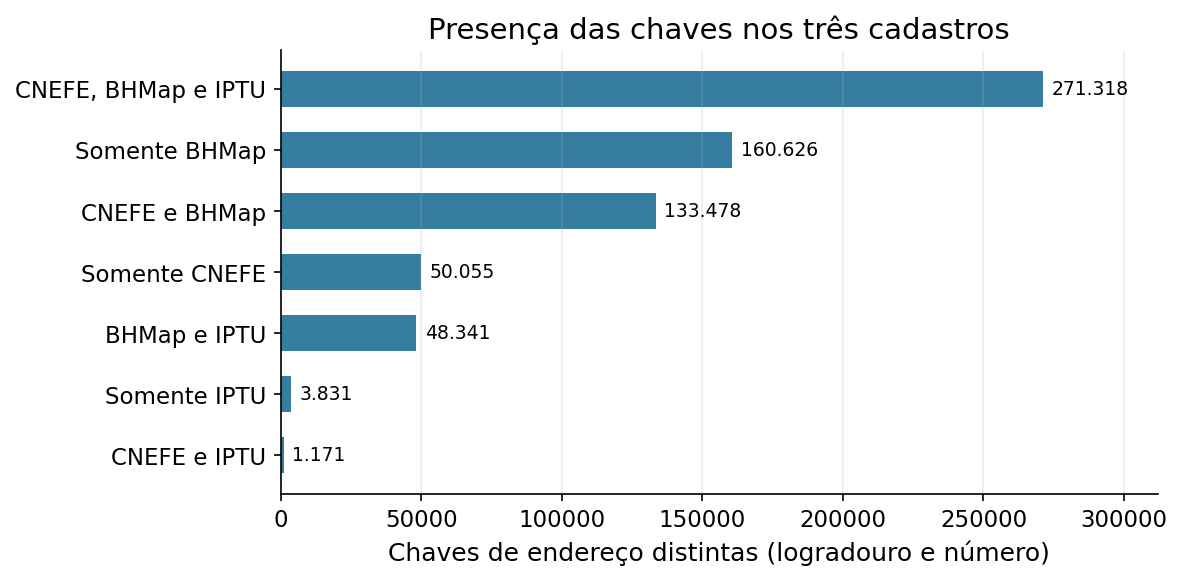

In [3]:
rot = {(True,True,True):'CNEFE, BHMap e IPTU',(True,True,False):'CNEFE e BHMap',(True,False,True):'CNEFE e IPTU',(False,True,True):'BHMap e IPTU',
       (True,False,False):'Somente CNEFE',(False,True,False):'Somente BHMap',(False,False,True):'Somente IPTU'}
r = regioes.assign(rotulo=[rot[(a,b,c)] for a,b,c in zip(regioes.cnefe, regioes.bhmap, regioes.iptu)]).sort_values('chaves')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(r.rotulo, r.chaves, color='#367EA1', height=.6)
for y, v in enumerate(r.chaves):
    ax.text(v+3000, y, f'{v:,}'.replace(',', '.'), va='center', fontsize=9)
ax.set(xlabel='Chaves de endereço distintas (logradouro e número)', title='Presença das chaves nos três cadastros')
ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=.25); ax.set_xlim(0, r.chaves.max()*1.15)
fig.tight_layout(); fig.savefig(F/'nb16_tres_cadastros.png', dpi=200); plt.show()

O CNEFE tem 456.022 chaves distintas, o BHMap 613.763 e o IPTU 324.661. As três fontes compartilham 271.318 chaves. Das 51.226 chaves que o CNEFE tem e o BHMap não tem, 1.171 (2,3%) existem no cadastro fiscal. Das 208.967 que só o BHMap tem frente ao CNEFE, 48.341 (23,1%) existem no IPTU. Há ainda 3.831 chaves que só o IPTU registra.

A figura mostra o tamanho de cada combinação. Os conjuntos não formam uma matriz de confusão, porque sem verdade de campo não há falso positivo nem falso negativo. O terceiro cadastro, porém, arbitra parte das discordâncias. Uma chave exclusiva do CNEFE que o IPTU também registra é um endereço que falta ao BHMap, e não um excesso do CNEFE. A arbitragem tem alcance limitado porque o IPTU cobre o lote fiscal formal e quase não alcança vilas e favelas (seção 5).

## 2. Comportamento da evidência fiscal nos pares próximos

Antes de usar o lote fiscal como árbitro, é preciso saber como ele se comporta onde os dois cadastros já concordam. Para cada par formado pela chave, mede-se a distância de cada ponto ao lote mais próximo que o IPTU associa à mesma chave. A tolerância de 10 m acomoda o ponto do CNEFE coletado na calçada, fora do polígono do lote. As faixas até 10 m e de 10 a 100 m funcionam como controle, e a sensibilidade à tolerância (0, 5, 10 e 20 m) é reportada.

In [4]:
kl = pd.DataFrame({'chave': ki, 'NULOTCTM': iptu.NULOTCTM, 'logr': log_i}).dropna(subset=['chave']).drop_duplicates(['chave','NULOTCTM'])
print('lotes do IPTU sem polígono no CTM', (~kl.NULOTCTM.isin(lotes.index)).sum())
kl = kl[kl.NULOTCTM.isin(lotes.index)].copy()
centro = lotes.geometry.centroid
kl['cx'] = centro.reindex(kl.NULOTCTM).x.to_numpy(); kl['cy'] = centro.reindex(kl.NULOTCTM).y.to_numpy()
g = kl.groupby('chave')
disp_iptu = np.hypot(g.cx.max()-g.cx.min(), g.cy.max()-g.cy.min()).rename('dispersao_iptu_m')
par = ident.pareado_identidade & ident.ref_x.notna()
D = pd.DataFrame({'chave': kc[par], 'dist': ident.loc[par,'dist_identidade'],
                  'xc': cnefe.geometry.x[par], 'yc': cnefe.geometry.y[par],
                  'xb': ident.loc[par,'ref_x'], 'yb': ident.loc[par,'ref_y'],
                  'conciliada': log_c[par].ne(log_cc[par]), 'ambigua': ident.loc[par,'chave_ambigua'].astype(bool),
                  'NV_GEO_COORD': cnefe.loc[par,'NV_GEO_COORD']})
assert D.chave.notna().all()
D = D.join(disp_iptu, on='chave')
D['chave_no_iptu'] = D.chave.isin(set(kl.chave))
E = D[['chave','xc','yc','xb','yb']].reset_index().merge(kl[['chave','NULOTCTM']], on='chave')
geo = lotes.geometry.reindex(E.NULOTCTM).to_numpy()
E['dC'] = shapely.distance(shapely.points(E.xc.to_numpy(), E.yc.to_numpy()), geo)
E['dB'] = shapely.distance(shapely.points(E.xb.to_numpy(), E.yb.to_numpy()), geo)
iC = E.loc[E.groupby('index').dC.idxmin(), ['index','NULOTCTM','dC']].set_index('index').rename(columns={'NULOTCTM':'lote_chave_c'})
iB = E.loc[E.groupby('index').dB.idxmin(), ['index','NULOTCTM','dB']].set_index('index').rename(columns={'NULOTCTM':'lote_chave_b'})
D = D.join(iC).join(iB)
D['faixa'] = pd.cut(D.dist, [-np.inf, 10, 100, np.inf], labels=['ate 10 m', '10 a 100 m', 'acima de 100 m'])
linhas = []
for tol in [0, 5, 10, 20]:
    for faixa, s in D.groupby('faixa', observed=True):
        e = s[s.chave_no_iptu]
        linhas.append({'tolerancia_m': tol, 'faixa': faixa, 'pares': len(s), 'pares_com_chave_no_iptu': len(e),
                       'pct_com_chave_no_iptu': 100*len(e)/len(s), 'pct_cnefe_no_lote': 100*(e.dC<=tol).mean(),
                       'pct_bhmap_no_lote': 100*(e.dB<=tol).mean(), 'pct_ambos': 100*((e.dC<=tol)&(e.dB<=tol)).mean(),
                       'pct_nenhum': 100*((e.dC>tol)&(e.dB>tol)).mean()})
controle = pd.DataFrame(linhas)
controle.to_csv(T/'nb16_controle_evidencia.csv', index=False)
print(controle.round(2).to_string(index=False))

lotes do IPTU sem polígono no CTM 54


 tolerancia_m          faixa  pares  pares_com_chave_no_iptu  pct_com_chave_no_iptu  pct_cnefe_no_lote  pct_bhmap_no_lote  pct_ambos  pct_nenhum
            0       ate 10 m 539913                   419749                  77.74              20.30              98.44      20.25        1.51
            0     10 a 100 m 492356                   383134                  77.82              22.36              98.43      22.25        1.47
            0 acima de 100 m  29775                    18979                  63.74              48.64              94.58      48.35        5.13
            5       ate 10 m 539913                   419749                  77.74              73.43              98.96      73.32        0.93
            5     10 a 100 m 492356                   383134                  77.82              34.25              98.85      34.07        0.97
            5 acima de 100 m  29775                    18979                  63.74              50.30              94.78      49.

O BHMap está dentro do polígono do lote fiscal da própria chave em 98,4% dos pares próximos, mesmo com tolerância zero. O ponto do BHMap é posicionado sobre o lote, então BHMap e IPTU não são fontes independentes. Quando os dois concordam contra o CNEFE, a evidência é de que os dois cadastros municipais coincidem, não de que o CNEFE errou em campo.

O CNEFE fica dentro do lote em só 20,3% dos pares a até 10 m com tolerância zero, porque o recenseador registra o ponto na calçada, diante da fachada. Com 10 m de tolerância a proporção sobe para 99,2%, e os pares em que nenhum dos dois pontos está no lote da chave são 0,66%. A regra concorda com o que se espera onde os cadastros já coincidem, e 10 m é a tolerância adotada. Na cauda, 63,7% dos pares têm a chave no IPTU, contra 77,7% nos pares próximos. A falta de evidência fiscal já é mais frequente onde o deslocamento é grande.

## 3. Os pares acima de 100 m: coordenada ou casamento textual?

Cada par da cauda recebe um único veredito, em ordem de precedência. A ordem coloca primeiro as explicações que não envolvem erro de nenhuma fonte, depois o casamento textual, e só então a coordenada:

1. **imóvel extenso, mesmo lote**: os dois pontos estão a até 10 m do mesmo lote da chave, ou de lotes da chave que ocupam um único local no IPTU (dispersão até 100 m). O deslocamento é a escolha de pontos diferentes dentro de um mesmo imóvel grande.
2. **homonímia, chave em dois lugares**: a mesma chave textual existe em locais distintos. Vale qualquer uma de três evidências: os dois pontos junto a lotes distintos da chave, a mais de 100 m entre si, o par marcado como ambíguo no NB02 (mais de um candidato no BHMap), ou os dois pontos sobre trechos desconectados de vias com o mesmo nome.
3. **CNEFE fora do lote fiscal**: o BHMap está no lote que o IPTU atribui à chave e o CNEFE não. Os dois cadastros municipais concordam contra a coordenada do CNEFE.
4. **BHMap fora do lote fiscal**: o caso simétrico.
5. Sem a chave no IPTU, recorre-se aos eixos nomeados (camada de declividade por trecho, 98% dos nomes do BHMap): **grafia conciliada sem confirmação** quando o casamento dependeu da conciliação aproximada, **mesma via sem lote fiscal** quando os dois pontos estão a até 40 m de um mesmo trecho contínuo da via, e **CNEFE fora da via nomeada** quando o ponto do CNEFE está a mais de 40 m de qualquer trecho com aquele nome.
6. O restante é **indeterminado**.

Os trechos de mesmo nome são unidos por proximidade de 50 m (buffer de 25 m). Componentes desconectados de um mesmo nome indicam vias homônimas.

In [5]:
via = gpd.read_parquet(P/'declividade.parquet', columns=['NOME_LOGRA','geometry'])
lv, _ = chave_identidade(via.NOME_LOGRA.fillna(''), pd.Series(['0']*len(via)))
mapa_v = conciliar_logradouros(lv.unique(), log_b.unique(), limiar=90, margem=2)
via['logr'] = lv.map(lambda v: mapa_v.get(v, v)).to_numpy()
print('nomes do BHMap com eixo nomeado', round(100*pd.Series(log_b.unique()).isin(set(via.logr)).mean(), 2), '%')
comp = []
for nome, gv in via.groupby('logr'):
    u = shapely.union_all(shapely.buffer(gv.geometry.to_numpy(), 25))
    partes = list(getattr(u, 'geoms', [u]))
    comp += [(nome, i, len(partes), p) for i, p in enumerate(partes)]
comp = gpd.GeoDataFrame(comp, columns=['logr','componente','n_componentes','geometry'], crs=via.crs)
print('nomes com mais de um trecho desconectado', round(100*(comp.drop_duplicates('logr').n_componentes>1).mean(), 2), '%')

def adjudicar(D, tol=TOL, via_m=15):
    s = D.copy()
    s['logr'] = s.chave.str.split('|').str[0]
    E = s[['logr','xc','yc','xb','yb']].reset_index().merge(comp, on='logr')
    gg = E.geometry.to_numpy()
    E['dvc'] = shapely.distance(shapely.points(E.xc.to_numpy(), E.yc.to_numpy()), gg)
    E['dvb'] = shapely.distance(shapely.points(E.xb.to_numpy(), E.yb.to_numpy()), gg)
    vc = E.loc[E.groupby('index').dvc.idxmin(), ['index','componente','dvc']].set_index('index').rename(columns={'componente':'comp_c'})
    vb = E.loc[E.groupby('index').dvb.idxmin(), ['index','componente','dvb']].set_index('index').rename(columns={'componente':'comp_b'})
    s = s.join(vc).join(vb)
    c_lote, b_lote = s.dC <= tol, s.dB <= tol
    c_via, b_via = s.dvc <= via_m, s.dvb <= via_m
    disp = s.dispersao_iptu_m.fillna(0)
    mesmo_lote = c_lote & b_lote & (s.lote_chave_c.eq(s.lote_chave_b) | (disp <= 100))
    homonimia = (c_lote & b_lote & ~mesmo_lote) | s.ambigua | (c_via & b_via & s.comp_c.ne(s.comp_b))
    ev = s.chave_no_iptu
    s['veredito'] = np.select([
        mesmo_lote, homonimia, ~c_lote & b_lote, c_lote & ~b_lote,
        ~ev & s.conciliada, ~ev & c_via & b_via, ~ev & ~c_via],
        ['imovel extenso, mesmo lote', 'homonimia, chave em dois lugares', 'CNEFE fora do lote fiscal',
         'BHMap fora do lote fiscal', 'grafia conciliada sem confirmacao', 'mesma via sem lote fiscal',
         'CNEFE fora da via nomeada'], 'indeterminado')
    natureza = {'imovel extenso, mesmo lote': 'nenhuma das duas', 'homonimia, chave em dois lugares': 'casamento textual',
                'grafia conciliada sem confirmacao': 'casamento textual', 'CNEFE fora do lote fiscal': 'coordenada do CNEFE',
                'CNEFE fora da via nomeada': 'coordenada ou endereco do CNEFE', 'BHMap fora do lote fiscal': 'referencia BHMap',
                'mesma via sem lote fiscal': 'posicao ao longo da via', 'indeterminado': 'indeterminado'}
    s['natureza'] = s.veredito.map(natureza)
    return s

cauda = adjudicar(D[D.dist > 100])
tab = cauda.groupby(['natureza','veredito']).dist.agg(pares='size', mediana_m='median', p90_m=lambda x: x.quantile(.9)).reset_index()
tab['pct_cauda'] = 100*tab.pares/len(cauda)
tab['pct_conciliada'] = tab.veredito.map(cauda.groupby('veredito').conciliada.mean()*100)
tab = tab.sort_values('pares', ascending=False)
tab.to_csv(T/'nb16_veredito_cauda.csv', index=False)
nat = cauda.groupby('natureza').size().rename('pares').to_frame().assign(pct=lambda x: 100*x.pares/len(cauda)).sort_values('pares', ascending=False)
nat.to_csv(T/'nb16_natureza_cauda.csv')
print('pares na cauda', len(cauda)); print(tab.round(1).to_string(index=False)); print(nat.round(2).to_string())

nomes do BHMap com eixo nomeado 96.75 %


nomes com mais de um trecho desconectado 10.39 %


pares na cauda 29775
                       natureza                          veredito  pares  mediana_m   p90_m  pct_cauda  pct_conciliada
               nenhuma das duas        imovel extenso, mesmo lote   9521      129.3   191.4       32.0             0.1
            coordenada do CNEFE         CNEFE fora do lote fiscal   7662      171.3   955.9       25.7             3.6
              casamento textual  homonimia, chave em dois lugares   5515     4744.6 15749.9       18.5            27.5
coordenada ou endereco do CNEFE         CNEFE fora da via nomeada   3760     2230.2 18211.8       12.6             0.0
        posicao ao longo da via         mesma via sem lote fiscal   2162      162.2   516.8        7.3             0.0
              casamento textual grafia conciliada sem confirmacao    914     4545.7 14482.8        3.1           100.0
                  indeterminado                     indeterminado    150      338.2 15496.8        0.5             4.0
               referencia B

In [6]:
fora = cauda[cauda.veredito == 'CNEFE fora do lote fiscal']
pc = gpd.GeoDataFrame(geometry=gpd.points_from_xy(fora.xc, fora.yc), index=fora.index, crs=cnefe.crs)
perto = gpd.sjoin_nearest(pc, lotes.reset_index()[['NULOTCTM','geometry']], how='left', max_distance=TOL)
perto = perto[~perto.index.duplicated()].NULOTCTM
logr_lote = kl.groupby('NULOTCTM').logr.agg(set)
mesmo = [isinstance(l, str) and l in logr_lote.index and lg in logr_lote[l] for l, lg in zip(perto, fora.logr)]
extenso = cauda[cauda.veredito == 'imovel extenso, mesmo lote']
lx = lotes.reindex(extenso.lote_chave_c.unique())
b = shapely.bounds(shapely.minimum_rotated_rectangle(lx.geometry.to_numpy()))
diag = pd.Series(np.hypot(b[:,2]-b[:,0], b[:,3]-b[:,1]), index=lx.index)
detalhe = {'cnefe_fora_lote_n': len(fora), 'cnefe_fora_lote_em_lote_do_mesmo_logradouro_pct': 100*np.mean(mesmo),
           'cnefe_fora_lote_sem_lote_a_10m_pct': 100*perto.isna().mean(), 'cnefe_fora_lote_mediana_m': fora.dist.median(),
           'extenso_n': len(extenso), 'extenso_area_mediana_m2': lx.AREA_M2.reindex(extenso.lote_chave_c).median(),
           'extenso_diagonal_mediana_m': diag.reindex(extenso.lote_chave_c).median(),
           'extenso_desloc_ate_diagonal_mais_20m_pct': 100*(extenso.dist.to_numpy() <= diag.reindex(extenso.lote_chave_c).to_numpy()+20).mean(),
           'extenso_mesmo_lote_pct': 100*extenso.lote_chave_c.eq(extenso.lote_chave_b).mean()}
nv = pd.crosstab(cauda.natureza, cauda.NV_GEO_COORD, margins=True)
nv.to_csv(T/'nb16_cauda_nivel_coleta.csv')
print(json.dumps({k: round(float(v), 2) for k, v in detalhe.items()}, indent=1)); print(nv)

{
 "cnefe_fora_lote_n": 7662.0,
 "cnefe_fora_lote_em_lote_do_mesmo_logradouro_pct": 24.99,
 "cnefe_fora_lote_sem_lote_a_10m_pct": 4.32,
 "cnefe_fora_lote_mediana_m": 171.27,
 "extenso_n": 9521.0,
 "extenso_area_mediana_m2": 22639.3,
 "extenso_diagonal_mediana_m": 352.33,
 "extenso_desloc_ate_diagonal_mais_20m_pct": 99.99,
 "extenso_mesmo_lote_pct": 99.99
}
NV_GEO_COORD                         1     2    3    4    All
natureza                                                     
casamento textual                 6101   208   75   45   6429
coordenada do CNEFE               6480   899  197   86   7662
coordenada ou endereco do CNEFE   3424   298   33    5   3760
indeterminado                      149     0    0    1    150
nenhuma das duas                  5090  4045  370   16   9521
posicao ao longo da via           1869   227   33   33   2162
referencia BHMap                    74    15    0    2     91
All                              23187  5692  708  188  29775


In [7]:
sens = []
for tol in [5, 10, 20]:
    for via_m in [5, 15, 25]:
        s = adjudicar(D[D.dist > 100], tol=tol, via_m=via_m)
        for k, v in s.natureza.value_counts().items():
            sens.append({'tolerancia_lote_m': tol, 'distancia_via_m': via_m+25, 'natureza': k, 'pares': v, 'pct': 100*v/len(s)})
sens = pd.DataFrame(sens)
sens.to_csv(T/'nb16_sensibilidade_tolerancia.csv', index=False)
print(sens.pivot_table(index='natureza', columns=['tolerancia_lote_m','distancia_via_m'], values='pct').round(1).to_string())

tolerancia_lote_m                  5                 10                20            
distancia_via_m                    30    40    50    30    40    50    30    40    50
natureza                                                                             
casamento textual                21.2  21.6  21.7  21.2  21.6  21.7  21.2  21.6  21.8
coordenada do CNEFE              26.0  25.8  25.8  25.9  25.7  25.7  24.7  24.5  24.5
coordenada ou endereco do CNEFE  13.3  12.6  12.2  13.3  12.6  12.2  13.3  12.6  12.2
indeterminado                     0.9   0.8   0.8   0.6   0.5   0.5   0.5   0.3   0.3
nenhuma das duas                 31.7  31.7  31.7  32.0  32.0  32.0  33.2  33.2  33.2
posicao ao longo da via           6.7   7.3   7.5   6.7   7.3   7.5   6.7   7.3   7.5
referencia BHMap                  0.2   0.2   0.2   0.3   0.3   0.3   0.4   0.4   0.4


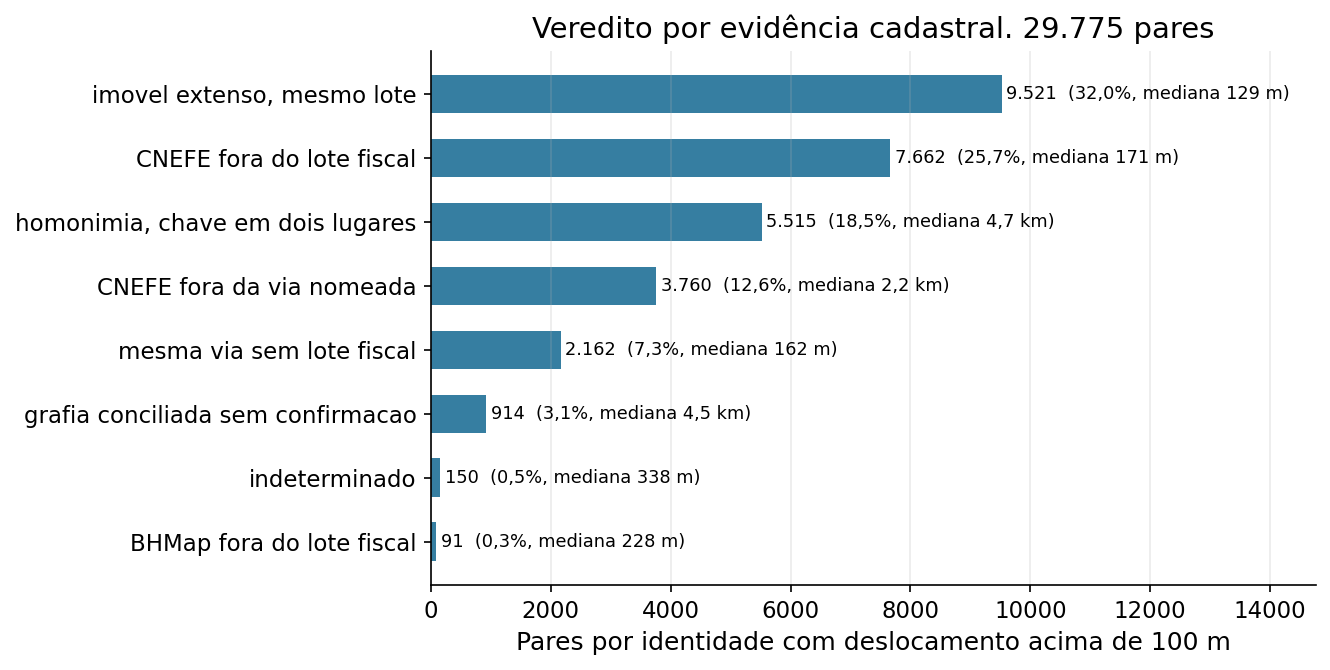

In [8]:
ordem = tab.sort_values('pares')
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(ordem.veredito, ordem.pares, color='#367EA1', height=.6)
for y, (n, p, m) in enumerate(zip(ordem.pares, ordem.pct_cauda, ordem.mediana_m)):
    med = f'{m/1000:.1f} km'.replace('.', ',') if m >= 1000 else f'{m:.0f} m'
    ax.text(n+80, y, f'{n:,}'.replace(',', '.')+f'  ({p:.1f}%, mediana {med})'.replace('.', ','), va='center', fontsize=8.5)
ax.set(xlabel='Pares por identidade com deslocamento acima de 100 m', title=f'Veredito por evidência cadastral, {len(cauda):,} pares'.replace(',', '.'))
ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=.25); ax.set_xlim(0, ordem.pares.max()*1.55)
fig.tight_layout(); fig.savefig(F/'nb16_veredito_cauda.png', dpi=200); plt.show()

Dos 29.775 pares formados pela chave com deslocamento acima de 100 m, 9.521 (32,0%) são imóveis extensos: os dois pontos estão junto ao mesmo lote fiscal, com área mediana de 22.639 m² e diagonal mediana de 352 m. Em 99,99% deles o deslocamento cabe na diagonal do lote mais 20 m. São condomínios e conjuntos em que cada fonte escolheu um ponto diferente dentro do mesmo imóvel. Não há erro de coordenada nem de casamento, e a mediana de 129 m mostra que esses casos se acumulam logo acima do limiar.

O casamento textual explica 6.429 pares (21,6%), com deslocamento mediano de 4,7 km na homonímia e 4,5 km na grafia conciliada sem confirmação. São chaves como RUA QUATRO, 45 ou RUA DO CRUZEIRO, 35, que existem em mais de um lugar da cidade. A distância de quilômetros é a assinatura do casamento errado, não de erro de GPS.

A coordenada do CNEFE diverge dos dois cadastros municipais em 7.662 pares (25,7%), com mediana de 171 m. Em 25,0% deles o ponto do CNEFE está junto a um lote do mesmo logradouro com outro número, o que sugere posição ao longo da via ou numeração divergente. Outros 3.760 pares (12,6%) não têm a chave no IPTU e o ponto do CNEFE está a mais de 40 m de qualquer trecho com o nome da via. Esses podem ser coordenada ou endereço errado no próprio CNEFE, e a evidência disponível não separa os dois. O caso simétrico, BHMap fora do lote fiscal, é raro: 91 pares (0,3%).

A figura resume a divisão, com o número de pares, a parcela e a distância mediana de cada classe. Cerca de um terço da cauda não é erro de nenhuma das fontes, um quarto é coordenada do CNEFE, um quinto é casamento textual, e o restante se divide entre casos que a evidência não separa (12,6% e 7,3%) e indeterminados (0,5%). As proporções variam menos de dois pontos percentuais entre as nove combinações de tolerância testadas. O nível de coleta não explica a cauda: 78% dos pares acima de 100 m têm NV_GEO_COORD igual a 1, coordenada original do Censo.

## 4. Inspeção visual de casos por veredito

A regra é verificável no mapa. O painel mostra, para três casos sorteados de cada veredito principal, os lotes do CTM, as edificações, os lotes que o IPTU associa à chave (contorno laranja), o ponto do CNEFE e o do BHMap. Quando o BHMap está fora da janela de 300 m, uma seta indica a direção e a distância. A inspeção serve para conferir se a regra descreve o que o mapa mostra, não substitui a verificação em campo.

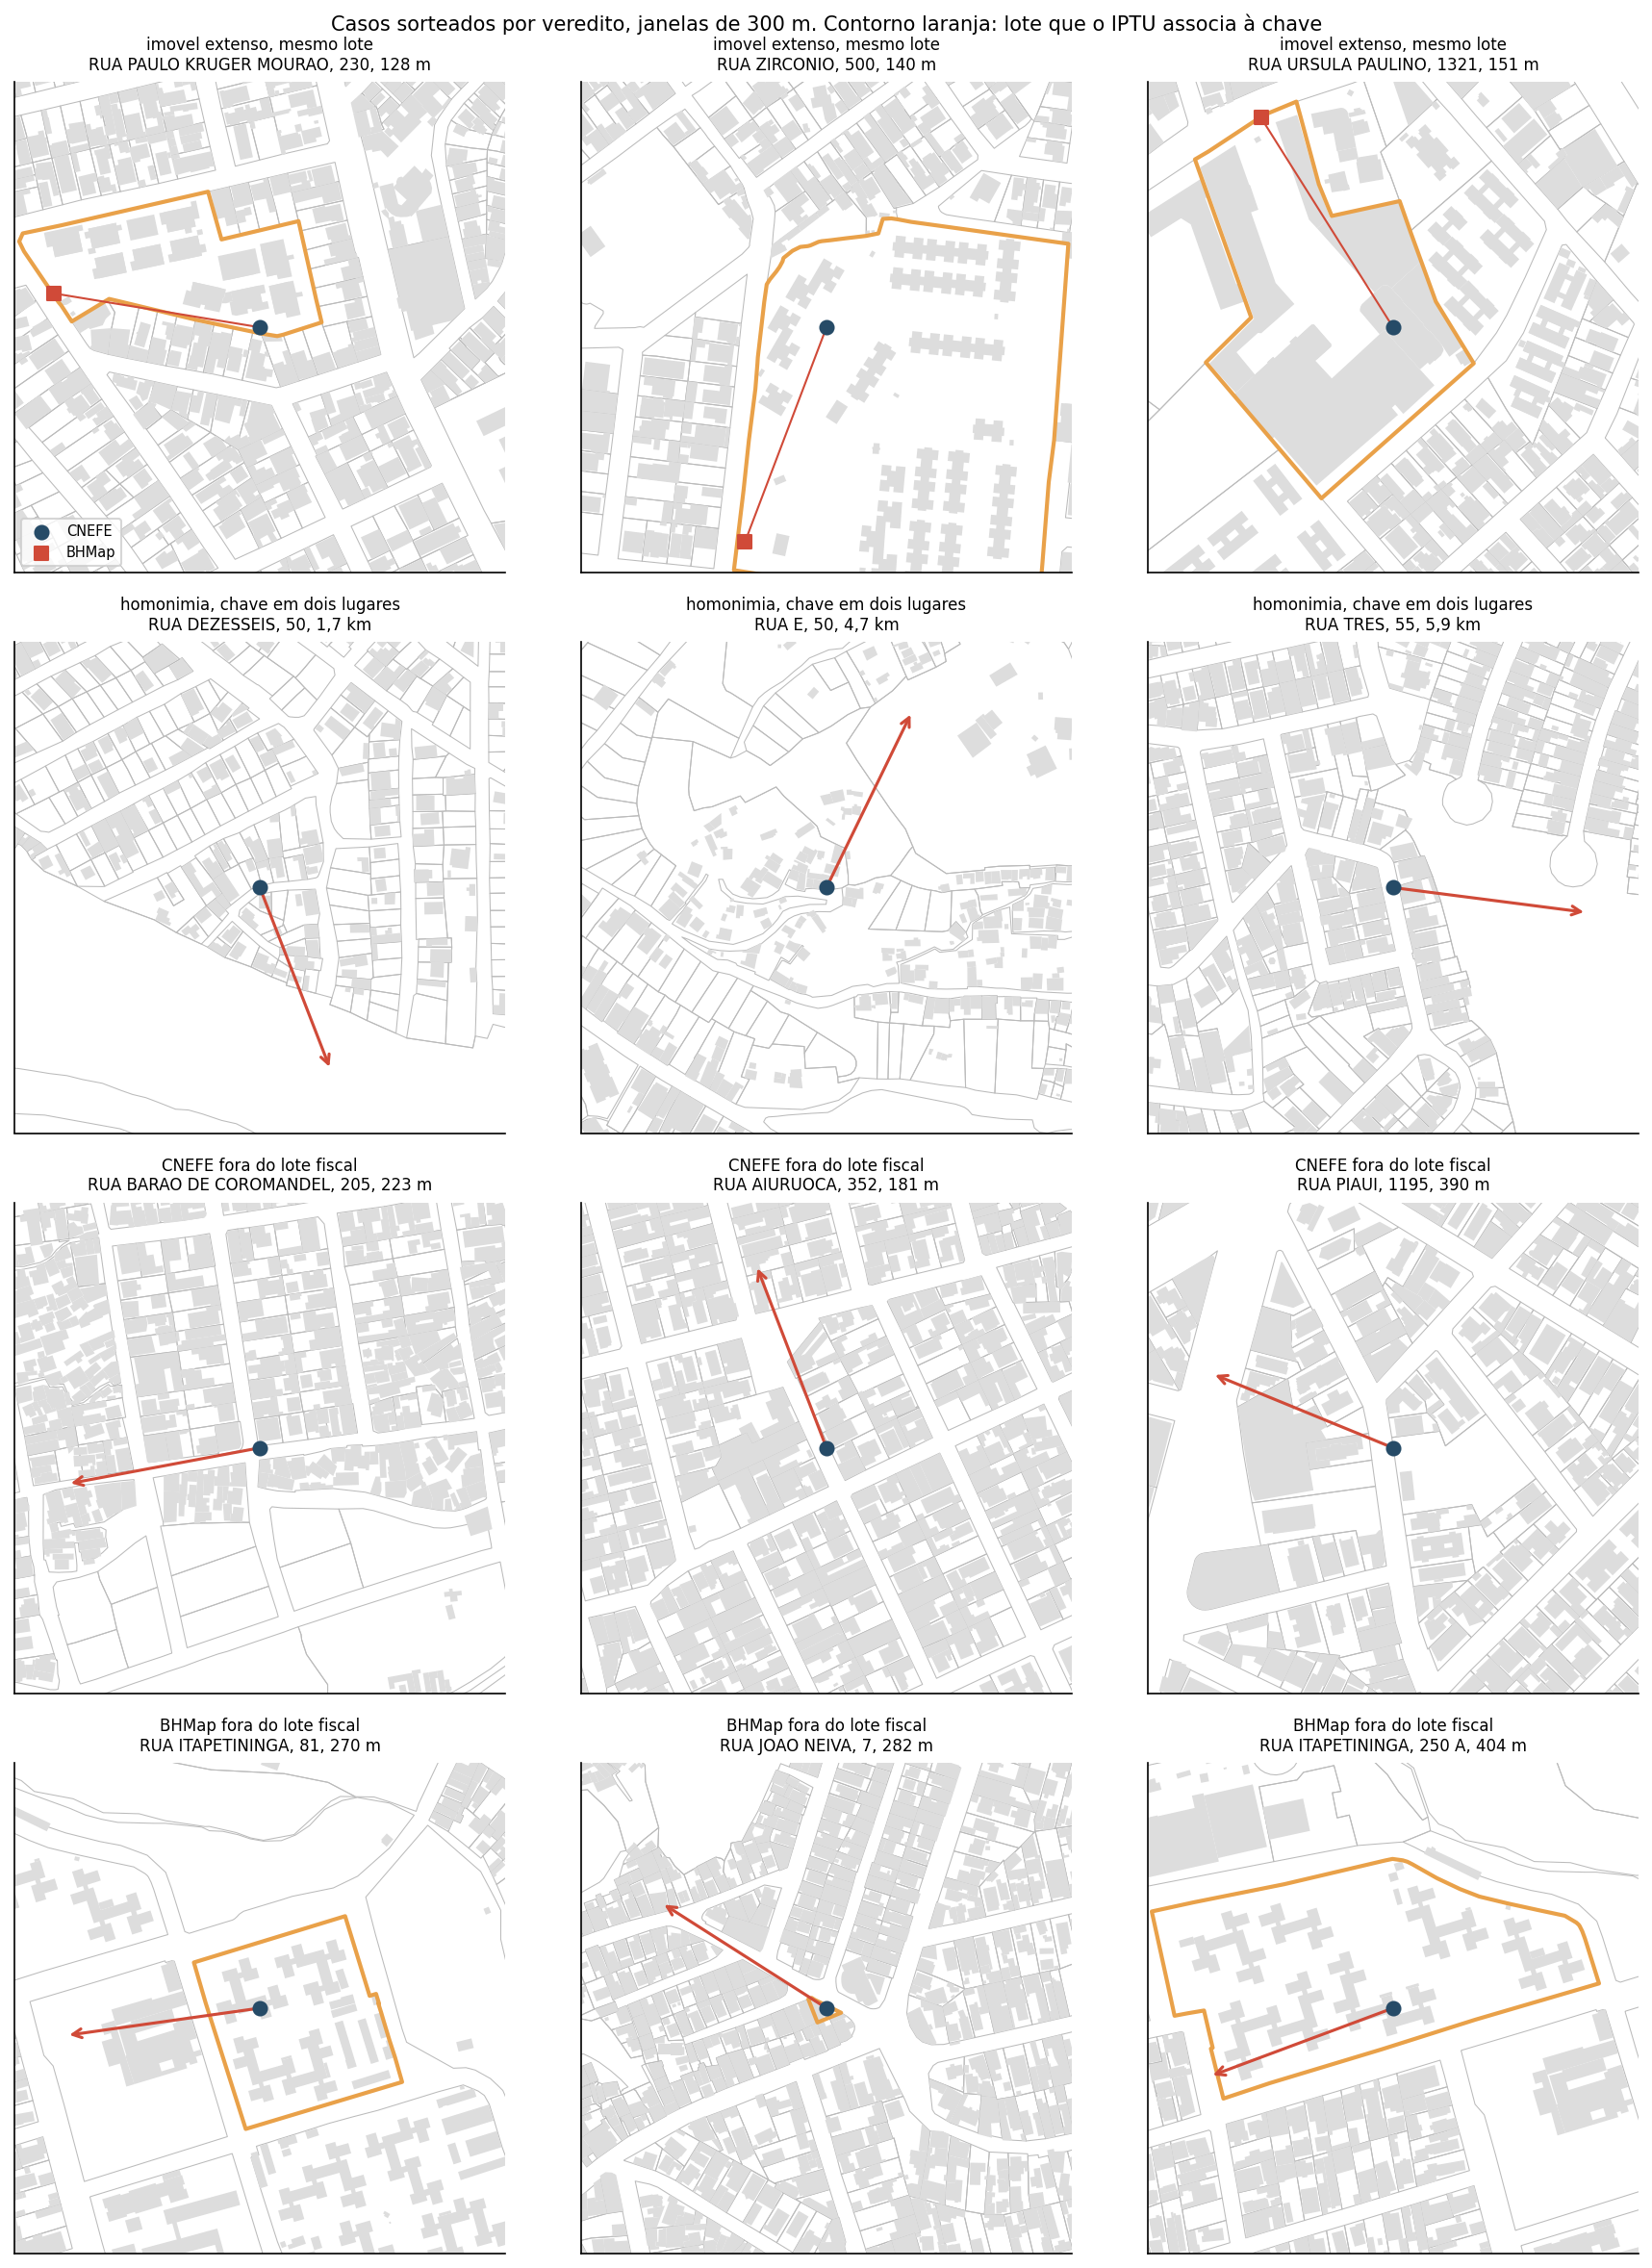

In [9]:
edif = gpd.read_parquet(P/'edificacao.parquet', columns=['geometry'])
mostrar = ['imovel extenso, mesmo lote', 'homonimia, chave em dois lugares', 'CNEFE fora do lote fiscal', 'BHMap fora do lote fiscal']
casos = pd.concat([cauda[cauda.veredito == v].sample(3, random_state=RANDOM_STATE) for v in mostrar])
end = cnefe.loc[casos.index, 'LOGRAD_NUM']
fig, axes = plt.subplots(len(mostrar), 3, figsize=(12, 16))
R = 150
for ax, (i, c) in zip(axes.ravel(), casos.iterrows()):
    caixa = shapely.box(c.xc-R, c.yc-R, c.xc+R, c.yc+R)
    lotes.iloc[lotes.sindex.query(caixa)].plot(ax=ax, facecolor='none', edgecolor='#BBBBBB', linewidth=.5)
    edif.iloc[edif.sindex.query(caixa)].plot(ax=ax, color='#DDDDDD', linewidth=0)
    lk = lotes.reindex(kl.loc[kl.chave == c.chave, 'NULOTCTM'])
    lk = lk[lk.intersects(caixa)]
    if len(lk): lk.plot(ax=ax, facecolor='none', edgecolor=COR_LOTE, linewidth=2)
    ax.scatter(c.xc, c.yc, s=45, color=COR_CNEFE, zorder=5, label='CNEFE')
    if abs(c.xb-c.xc) < R and abs(c.yb-c.yc) < R:
        ax.scatter(c.xb, c.yb, s=45, color=COR_BHMAP, marker='s', zorder=5, label='BHMap')
        ax.plot([c.xc, c.xb], [c.yc, c.yb], color=COR_BHMAP, linewidth=1)
    else:
        u = np.array([c.xb-c.xc, c.yb-c.yc]); u = u/np.linalg.norm(u)*R*.8
        ax.annotate('', xy=(c.xc+u[0], c.yc+u[1]), xytext=(c.xc, c.yc), arrowprops=dict(arrowstyle='->', color=COR_BHMAP, lw=1.5))
    dist = f'{c.dist/1000:.1f} km'.replace('.', ',') if c.dist >= 1000 else f'{c.dist:.0f} m'
    ax.set_title(f'{c.veredito}\n{end[i]}, {dist}', fontsize=8)
    ax.set_xlim(c.xc-R, c.xc+R); ax.set_ylim(c.yc-R, c.yc+R); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
axes[0,0].legend(fontsize=7, loc='lower left')
fig.suptitle('Casos sorteados por veredito, janelas de 300 m. Contorno laranja: lote que o IPTU associa à chave', fontsize=10)
fig.tight_layout(); fig.savefig(F/'nb16_painel_casos.png', dpi=170); plt.show()
casos.assign(endereco=end)[['endereco','chave','dist','veredito','dC','dB','dispersao_iptu_m']].to_csv(T/'nb16_painel_casos.csv')

Os doze casos sorteados confirmam a regra no mapa. Nos imóveis extensos, os dois pontos caem no mesmo polígono laranja de um conjunto habitacional. Na homonímia, o CNEFE está numa via com o nome da chave e o BHMap está longe, em outra via de mesmo nome. Em CNEFE fora do lote fiscal, o BHMap está no lote laranja e o CNEFE não. Em BHMap fora do lote, ocorre o inverso.

A regra dá prioridade ao mesmo lote: um par com os dois pontos no mesmo lote é imóvel extenso, mesmo que a chave também exista em outro lote distante. A inspeção de doze casos verifica a coerência da regra, sem estimar sua taxa de acerto.

## 5. Endereço sem par no BHMap é dado espúrio?

A mesma evidência responde em parte a essa pergunta. Um registro do CNEFE cuja chave não existe no BHMap, mas que está a até 10 m de um lote que o IPTU associa a essa mesma chave, é um endereço reconhecido pelo cadastro fiscal da prefeitura e ausente apenas do BHMap. A recíproca não vale: não estar no IPTU não torna o registro espúrio, sobretudo em vilas e favelas, onde o cadastro fiscal quase não chega.

In [10]:
vf = gpd.read_parquet(P/'vila_favela.parquet').to_crs(cnefe.crs).dissolve()
fav = gpd.sjoin(cnefe[['geometry']], vf[['geometry']], how='left', predicate='within')['index_right'].notna()
fav = fav[~fav.index.duplicated()].reindex(cnefe.index)
so_c = kc.notna() & ~kc.isin(SB)
E = pd.DataFrame({'chave': kc[so_c], 'x': cnefe.geometry.x[so_c], 'y': cnefe.geometry.y[so_c]}).reset_index().merge(kl[['chave','NULOTCTM']], on='chave')
E['d'] = shapely.distance(shapely.points(E.x.to_numpy(), E.y.to_numpy()), lotes.geometry.reindex(E.NULOTCTM).to_numpy())
dmin = E.groupby('index').d.min().reindex(cnefe.index)
S = pd.DataFrame({'em_favela': fav, 'chave_no_iptu': kc.isin(SI), 'confirmado_lote_10m': dmin.le(TOL),
                  'especie': cnefe.COD_ESPECIE.map(config.ESPECIE_MAP)})[so_c]
def resumo(g):
    return pd.Series({'registros': len(g), 'chave_no_iptu': int(g.chave_no_iptu.sum()), 'pct_chave_no_iptu': 100*g.chave_no_iptu.mean(),
                      'confirmados_no_lote': int(g.confirmado_lote_10m.sum()), 'pct_confirmados_no_lote': 100*g.confirmado_lote_10m.mean()})
somente = pd.concat([resumo(S).to_frame('todos').T, S.groupby('em_favela').apply(resumo).rename(index={True:'dentro de vila ou favela', False:'fora de vila ou favela'}),
                     S.groupby('especie').apply(resumo)])
somente.to_csv(T/'nb16_somente_cnefe_confirmacao.csv')
so_b = kb.notna() & ~kb.isin(SC)
somente_bhmap = {'registros_somente_bhmap': int(so_b.sum()), 'com_chave_no_iptu': int(kb[so_b].isin(SI).sum()), 'pct': 100*kb[so_b].isin(SI).mean()}
print(somente.round(2).to_string()); print(somente_bhmap)

                          registros  chave_no_iptu  pct_chave_no_iptu  confirmados_no_lote  pct_confirmados_no_lote
todos                       95706.0         4024.0               4.20               3082.0                     3.22
fora de vila ou favela      65273.0         3973.0               6.09               3056.0                     4.68
dentro de vila ou favela    30433.0           51.0               0.17                 26.0                     0.09
Domicílio Coletivo             84.0            1.0               1.19                  1.0                     1.19
Domicílio Particular        81630.0         3618.0               4.43               2819.0                     3.45
Em Construção                2363.0           46.0               1.95                 37.0                     1.57
Estab. Agropecuário            11.0            0.0               0.00                  0.0                     0.00
Estab. Ensino                 136.0            4.0               2.94   

Dos 95.706 registros do CNEFE cuja chave não existe no BHMap, só 3.082 (3,2%) estão a até 10 m de um lote que o IPTU associa à mesma chave, e fora de vilas e favelas a proporção é de 4,7%. Com todos os pontos do BHMap na referência, quase todos os registros que o cadastro fiscal reconhecia passaram a encontrar par. Os 3.082 que restam não são espúrios: são endereços que o cadastro fiscal reconhece no mesmo local e que faltam ao BHMap.

Dentro de vilas e favelas, só 0,17% desses registros têm a chave no IPTU e 0,09% são confirmados no lote. Ali a falta de evidência fiscal não diz nada sobre o CNEFE, porque o cadastro fiscal não alcança o território, e é ali que está um terço dos registros sem par. Os demais registros sem par continuam sem veredito. A resposta à pergunta sobre dado espúrio é não para esses 3.082 registros, e indeterminada para o resto. Na direção inversa, 23,5% dos 226.432 pontos exclusivos do BHMap têm a chave no IPTU. O [NB22](22_conjuntos_exclusivos.ipynb) separa, entre as chaves só do BHMap, as que aparecem apenas em pontos a confirmar.

## 6. Números absolutos por etapa e por segmento

Esta seção reúne os números absolutos de cada base, do arquivo de entrada à chave de comparação, e os mesmos números nos segmentos de apartamentos, estabelecimentos e vilas e favelas. A primeira tabela segue cada base etapa por etapa. A segunda abre os registros do CNEFE por segmento: quantos têm chave comum com o BHMap, quantos são exclusivos, quantos desses exclusivos o cadastro fiscal confirma no lote e como a cauda acima de 100 m se divide entre as naturezas da Seção 3. A unidade é o registro, salvo onde a coluna diz chave.

In [11]:
bh_total = gpd.read_parquet(P/'bhmap_bh.parquet', columns=['EXISTENCIA','geometry'])
etapas = pd.DataFrame([
    ('CNEFE', 'registros de BH no arquivo do IBGE', 'recorte municipal do arquivo de MG', len(cnefe)),
    ('CNEFE', 'com chave de logradouro e numero', 'forma canonica, primeiro numero, conciliacao 90/2', int(kc.notna().sum())),
    ('CNEFE', 'chaves distintas', '', len(SC)),
    ('CNEFE', 'registros com chave comum ao BHMap', 'pareamento por identidade', int(kc.isin(SB).sum())),
    ('CNEFE', 'registros com chave exclusiva', '', int((kc.notna() & ~kc.isin(SB)).sum())),
    ('CNEFE', 'registros sem chave valida', 'sem numero interpretavel', int(kc.isna().sum())),
    ('BHMap', 'pontos de endereco', 'arquivo integral', len(bh_total)),
    ('BHMap', 'pontos com placa', 'atributo EXISTENCIA = Sim, sem filtrar', int(bh_total.EXISTENCIA.eq('Sim').sum())),
    ('BHMap', 'com chave de logradouro e numero', 'tipo e nome concatenados, forma canonica', int(kb.notna().sum())),
    ('BHMap', 'chaves distintas', '', len(SB)),
    ('BHMap', 'registros com chave comum ao CNEFE', '', int(kb.isin(SC).sum())),
    ('BHMap', 'registros com chave exclusiva', '', int((kb.notna() & ~kb.isin(SC)).sum())),
    ('IPTU', 'unidades do cadastro imobiliario', 'arquivo integral', len(iptu)),
    ('IPTU', 'lotes distintos', '', iptu.NULOTCTM.nunique()),
    ('IPTU', 'unidades com chave valida', 'tipo expandido, conciliacao ao BHMap 90/2', int(ki.notna().sum())),
    ('IPTU', 'chaves distintas', '', len(SI)),
    ('IPTU', 'pares chave e lote com poligono CTM', '', len(kl))], columns=['base','etapa','tratamento','n'])
etapas.to_csv(T/'nb16_etapas_absolutas.csv', index=False)
print(etapas.to_string(index=False))

seg = pd.DataFrame({'chave': kc, 'comum': kc.isin(SB), 'exclusiva': kc.notna() & ~kc.isin(SB),
                    'confirmada_iptu': dmin.le(TOL) & kc.notna() & ~kc.isin(SB), 'em_favela': fav,
                    'apartamento': cnefe.COD_TIPO_ESPECI.eq(103).fillna(False),
                    'estabelecimento': cnefe.COD_ESPECIE.isin([3,4,5,6,8]),
                    'pareado': ident.pareado_identidade, 'dist': ident.dist_identidade})
seg = seg.join(cauda.natureza.rename('natureza_cauda'))
segmentos = {'todos': seg.index == seg.index, 'apartamentos (vertical)': seg.apartamento, 'casas e demais domicilios': ~seg.apartamento & ~seg.estabelecimento,
             'estabelecimentos': seg.estabelecimento, 'em vila ou favela': seg.em_favela, 'fora de vila ou favela': ~seg.em_favela}
linhas = []
for nome, m in segmentos.items():
    g = seg[m]; p = g[g.pareado]
    linhas.append({'segmento': nome, 'registros': len(g), 'chaves_distintas': g.chave.nunique(),
                   'registros_chave_comum': int(g.comum.sum()), 'pct_comum': 100*g.comum.mean(),
                   'registros_chave_exclusiva': int(g.exclusiva.sum()), 'exclusivos_confirmados_iptu': int(g.confirmada_iptu.sum()),
                   'pct_exclusivos_confirmados': 100*g.confirmada_iptu.sum()/max(g.exclusiva.sum(), 1),
                   'mediana_desloc_m': p.dist.median(), 'cauda_100m': int(p.dist.gt(100).sum()), 'pct_cauda': 100*p.dist.gt(100).mean(),
                   **{f'cauda_{k}': int((g.natureza_cauda == k).sum()) for k in ['nenhuma das duas','casamento textual','coordenada do CNEFE','coordenada ou endereco do CNEFE']}})
segmentos_tab = pd.DataFrame(linhas)
segmentos_tab.to_csv(T/'nb16_segmentos_absolutos.csv', index=False)
bh_fav = gpd.sjoin(bh[['geometry']], vf[['geometry']], how='left', predicate='within')['index_right'].notna()
bh_fav = bh_fav[~bh_fav.index.duplicated()].reindex(bh.index)
seg_b = pd.DataFrame([{'segmento': n, 'registros': int(m.sum()), 'chaves': kb[m].nunique(), 'registros_chave_comum': int((m & kb.isin(SC)).sum()),
                       'registros_chave_exclusiva': int((m & kb.notna() & ~kb.isin(SC)).sum()), 'exclusivos_com_chave_no_iptu': int((m & kb.notna() & ~kb.isin(SC) & kb.isin(SI)).sum())}
                      for n, m in [('todos', bh_fav | ~bh_fav), ('em vila ou favela', bh_fav), ('fora de vila ou favela', ~bh_fav)]])
seg_b.to_csv(T/'nb16_segmentos_bhmap.csv', index=False)
print(segmentos_tab.round(2).T.to_string()); print(seg_b.to_string(index=False))

 base                               etapa                                        tratamento       n
CNEFE  registros de BH no arquivo do IBGE                recorte municipal do arquivo de MG 1180102
CNEFE    com chave de logradouro e numero forma canonica, primeiro numero, conciliacao 90/2 1157750
CNEFE                    chaves distintas                                                    456022
CNEFE  registros com chave comum ao BHMap                         pareamento por identidade 1062044
CNEFE       registros com chave exclusiva                                                     95706
CNEFE          registros sem chave valida                          sem numero interpretavel   22352
BHMap                  pontos de endereco                                  arquivo integral  757113
BHMap                    pontos com placa            atributo EXISTENCIA = Sim, sem filtrar  515953
BHMap    com chave de logradouro e numero          tipo e nome concatenados, forma canonica  757113


                                             0                        1                          2                 3                  4                       5
segmento                                 todos  apartamentos (vertical)  casas e demais domicilios  estabelecimentos  em vila ou favela  fora de vila ou favela
registros                              1180102                   403623                     642844            133635             128149                 1051953
chaves_distintas                        456022                    37073                     369559            102420              69999                  392257
registros_chave_comum                  1062044                   385346                     561288            115410              92694                  969350
pct_comum                                 90.0                    95.47                      87.31             86.36              72.33                   92.15
registros_chave_exclusiva               

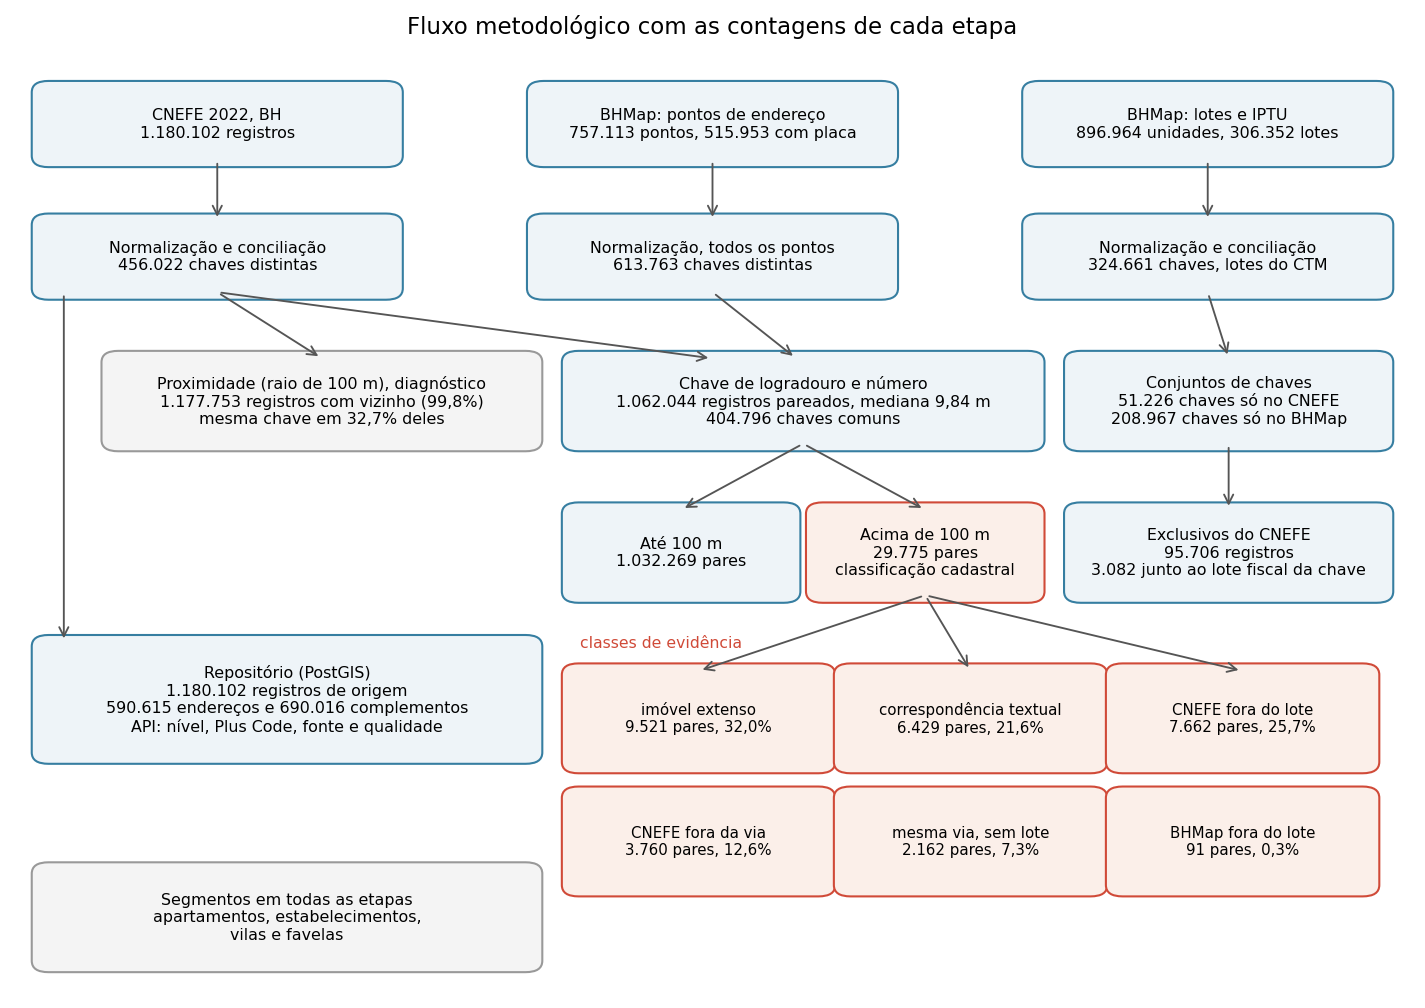

In [12]:
from matplotlib.patches import FancyBboxPatch
def caixa(ax, x, y, w, h, texto, cor='#EEF4F8', borda='#367EA1', fs=7.6):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.008,rounding_size=0.012', fc=cor, ec=borda, lw=1))
    ax.text(x+w/2, y+h/2, texto, ha='center', va='center', fontsize=fs)
def seta(ax, x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='->', color='#555555', lw=.9))
fmt = lambda v: f'{int(v):,}'.replace(',', '.')
e = etapas.set_index(['base','etapa']).n
s0 = segmentos_tab.set_index('segmento').loc['todos']
nat_n = cauda.natureza.value_counts()
fig, ax = plt.subplots(figsize=(12, 8.2)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
W, H = .25, .075
caixa(ax, .02, .88, W, H, f"CNEFE 2022, BH\n{fmt(e['CNEFE','registros de BH no arquivo do IBGE'])} registros")
caixa(ax, .375, .88, W, H, f"BHMap: pontos de endereço\n{fmt(e['BHMap','pontos de endereco'])} pontos, {fmt(e['BHMap','pontos com placa'])} com placa")
caixa(ax, .73, .88, W, H, f"BHMap: lotes e IPTU\n{fmt(e['IPTU','unidades do cadastro imobiliario'])} unidades, {fmt(e['IPTU','lotes distintos'])} lotes")
caixa(ax, .02, .74, W, H, f"Normalização e conciliação\n{fmt(len(SC))} chaves distintas")
caixa(ax, .375, .74, W, H, f"Normalização, todos os pontos\n{fmt(len(SB))} chaves distintas")
caixa(ax, .73, .74, W, H, f"Normalização e conciliação\n{fmt(len(SI))} chaves, lotes do CTM")
for x in [.02, .375, .73]: seta(ax, x+W/2, .88, x+W/2, .815)
prox = pd.read_csv(T/'nb02_taxa_matching.csv').iloc[0]
decomp = pd.read_csv(T/'nb02_decomposicao_pareamento.csv').set_index('Criterio')['% dos pares']
pct_prox = f"{prox.taxa_matching_pct:.1f}".replace('.', ',')
pct_id = f"{decomp['Identidade completa (logradouro e numero)']:.1f}".replace('.', ',')
caixa(ax, .07, .58, .30, .09, f"Proximidade (raio de 100 m), diagnóstico\n{fmt(prox.n_matched)} registros com vizinho ({pct_prox}%)\nmesma chave em {pct_id}% deles", cor='#F4F4F4', borda='#999999')
caixa(ax, .40, .58, .33, .09, f"Chave de logradouro e número\n{fmt(s0.registros_chave_comum)} registros pareados, mediana " + f"{D.dist.median():.2f}".replace('.', ',') + f" m\n{fmt(len(SC & SB))} chaves comuns")
caixa(ax, .76, .58, .22, .09, f"Conjuntos de chaves\n{fmt(len(SC - SB))} chaves só no CNEFE\n{fmt(len(SB - SC))} chaves só no BHMap")
seta(ax, .145, .74, .22, .67); seta(ax, .145, .74, .50, .67); seta(ax, .50, .74, .56, .67); seta(ax, .855, .74, .87, .67)
caixa(ax, .40, .42, .155, .09, f"Até 100 m\n{fmt(len(D) - len(cauda))} pares")
caixa(ax, .575, .42, .155, .09, f"Acima de 100 m\n{fmt(len(cauda))} pares\nclassificação cadastral", cor='#FBEFE9', borda='#D04A38')
caixa(ax, .76, .42, .22, .09, f"Exclusivos do CNEFE\n{fmt(s0.registros_chave_exclusiva)} registros\n{fmt(s0.exclusivos_confirmados_iptu)} junto ao lote fiscal da chave")
seta(ax, .565, .58, .4775, .51); seta(ax, .565, .58, .6525, .51); seta(ax, .87, .58, .87, .51)
rot = [('nenhuma das duas','imóvel extenso'), ('casamento textual','correspondência textual'), ('coordenada do CNEFE','CNEFE fora do lote'),
       ('coordenada ou endereco do CNEFE','CNEFE fora da via'), ('posicao ao longo da via','mesma via, sem lote'), ('referencia BHMap','BHMap fora do lote')]
for i, (k, r) in enumerate(rot):
    xi, y = .40 + (i % 3)*.195, .24 - (i // 3)*.13
    pct = f"{100*nat_n.get(k, 0)/len(cauda):.1f}".replace('.', ',')
    caixa(ax, xi, y, .18, .1, f"{r}\n{fmt(nat_n.get(k, 0))} pares, {pct}%", cor='#FBEFE9', borda='#D04A38', fs=7.2)
    if i < 3: seta(ax, .6525, .42, xi+.09, y+.1)
ax.text(.405, .365, 'classes de evidência', ha='left', fontsize=7.5, color='#D04A38')
caixa(ax, .02, .25, .35, .12, f"Repositório (PostGIS)\n{fmt(1180102)} registros de origem\n{fmt(590615)} endereços e {fmt(690016)} complementos\nAPI: nível, Plus Code, fonte e qualidade", cor='#EEF4F8')
seta(ax, .035, .74, .035, .37)
caixa(ax, .02, .03, .35, .1, "Segmentos em todas as etapas\napartamentos, estabelecimentos,\nvilas e favelas", cor='#F4F4F4', borda='#999999')
ax.set_title('Fluxo metodológico com as contagens de cada etapa', fontsize=11)
fig.savefig(F/'nb16_fluxo_metodologico.png', dpi=200, bbox_inches='tight'); plt.show()

Do arquivo do IBGE ao par pela chave, o CNEFE passa de 1.180.102 registros para 1.157.750 com chave válida, 22.352 sem número interpretável, 1.062.044 com chave comum ao BHMap e 95.706 com chave exclusiva. O BHMap entra com os 757.113 pontos, todos com chave, dos quais 515.953 têm placa, 530.681 têm chave comum ao CNEFE e 226.432 são exclusivos. O IPTU tem 896.964 unidades, 887.422 com chave válida.

Os segmentos contam histórias diferentes. Nos apartamentos, 95,5% dos registros têm chave comum, e 9,4% dos 17.628 exclusivos são confirmados no lote fiscal. A cauda dos apartamentos (14.523 pares, 3,77%) é em 64% imóvel extenso (9.308 pares), ou seja, representação de condomínio, e não erro. Nos estabelecimentos, 86,4% têm chave comum e a cauda é a menor dos segmentos, 1,69%. Em vilas e favelas, 72,3% têm chave comum, só 0,09% dos exclusivos são confirmados, e a cauda de 6,45% é em 57% casamento textual (3.377 de 5.977 pares). A coordenada do CNEFE responde por apenas 535 pares da cauda em favela. A cauda mais alta no território informal é, portanto, sobretudo efeito de homonímia de becos e vias sem denominação oficial única, e não de coordenada pior.

No BHMap, 124.671 pontos estão em vilas e favelas, e 51.875 deles têm chave exclusiva, dos quais só 2.045 aparecem no IPTU. A figura do fluxo reúne essas contagens na ordem das etapas.

## 7. Verticalização e representação: distância do ponto ao lote fiscal

A distância ponto a ponto entre CNEFE e BHMap mistura duas coisas: o erro da coordenada e a convenção de cada cadastro. O CNEFE registra o acesso ao imóvel, e o IBGE coloca os apartamentos de um mesmo número na mediana da face de quadra. O BHMap posiciona o ponto dentro do lote, como a seção 2 mostrou. Medir a distância do ponto do CNEFE ao lote que o IPTU associa ao próprio endereço retira a convenção do BHMap da conta. Para não misturar homonímia, a seção usa só chaves com um único lote no IPTU. O contraste entre apartamentos e os demais registros que não são estabelecimentos tem intervalo de 95% por reamostragem de blocos de 2 km. A distância ao lote vale zero para qualquer ponto dentro do polígono, então favorece lotes grandes, e os apartamentos ocupam lotes maiores. Por isso o contraste também é estimado dentro de quintis de área do lote, com a média das diferenças ponderada pela distribuição dos apartamentos entre os quintis.

In [13]:
n_lotes_chave = kl.groupby('chave').NULOTCTM.nunique()
chaves_um_lote = set(n_lotes_chave[n_lotes_chave.eq(1)].index)
R8 = D[D.chave.isin(chaves_um_lote)].join(seg[['apartamento','estabelecimento','em_favela']])
grupos = {'todos': R8.index == R8.index, 'apartamentos (vertical)': R8.apartamento,
          'casas e demais domicilios': ~R8.apartamento & ~R8.estabelecimento, 'estabelecimentos': R8.estabelecimento,
          'em vila ou favela': R8.em_favela, 'fora de vila ou favela': ~R8.em_favela,
          'NV 1 (original)': R8.NV_GEO_COORD.eq(1), 'NV 2 (agrupamento de apartamentos)': R8.NV_GEO_COORD.eq(2)}
def estat(s, rotulo):
    return {f'{rotulo}_mediana_m': s.median(), f'{rotulo}_ce90_m': s.quantile(.9), f'{rotulo}_acima30_pct': 100*s.gt(30).mean(), f'{rotulo}_acima100_pct': 100*s.gt(100).mean()}
pl = pd.DataFrame([{'grupo': g, 'pares': int(m.sum()), **estat(R8.dist[m], 'ponto_ponto'), **estat(R8.dC[m], 'ponto_lote'),
                    'cnefe_dentro_do_lote_pct': 100*R8.dC[m].eq(0).mean(), 'cnefe_ate_5m_do_lote_pct': 100*R8.dC[m].le(5).mean()} for g, m in grupos.items()])
pl.to_csv(T/'nb16_ponto_lote.csv', index=False)
R8['bloco'] = (R8.xc//2000).astype(int).astype(str)+'_'+(R8.yc//2000).astype(int).astype(str)
apto, casa = R8[R8.apartamento], R8[~R8.apartamento & ~R8.estabelecimento]
pos = {b: np.asarray(ix) for b, ix in R8.groupby('bloco').indices.items()}
blocos = list(pos)
rng = np.random.default_rng(RANDOM_STATE)
valores = R8[['dist','dC']].to_numpy(); ap = R8.apartamento.to_numpy(); ca = (~R8.apartamento & ~R8.estabelecimento).to_numpy()
reps = []
for _ in range(500):
    i = np.concatenate([pos[blocos[k]] for k in rng.integers(len(blocos), size=len(blocos))])
    v, a, c_ = valores[i], ap[i], ca[i]
    reps.append([np.median(v[a, 0]) - np.median(v[c_, 0]), np.median(v[a, 1]) - np.median(v[c_, 1])])
reps = np.array(reps)
contraste = pd.DataFrame({'medida': ['ponto_ponto', 'ponto_lote'],
                          'diferenca_mediana_apto_menos_casa_m': [apto.dist.median()-casa.dist.median(), apto.dC.median()-casa.dC.median()],
                          'ic95_inf': np.percentile(reps, 2.5, axis=0), 'ic95_sup': np.percentile(reps, 97.5, axis=0)})
R8['area_lote'] = lotes.AREA_M2.reindex(R8.lote_chave_c).to_numpy()
base_ac = R8[(R8.apartamento | (~R8.apartamento & ~R8.estabelecimento)) & R8.area_lote.notna()].copy()
base_ac['quintil_area'] = pd.qcut(base_ac.area_lote, 5, labels=False)
estratos = base_ac.groupby(['quintil_area', 'apartamento']).agg(pares=('dC','size'), area_mediana_m2=('area_lote','median'),
                     ponto_ponto_mediana_m=('dist','median'), ponto_lote_mediana_m=('dC','median'), dentro_do_lote_pct=('dC', lambda s: 100*s.eq(0).mean())).reset_index()
estratos.to_csv(T/'nb16_ponto_lote_estratos_area.csv', index=False)
q_ = base_ac.quintil_area.to_numpy(); a_ = base_ac.apartamento.to_numpy(); v_ = base_ac[['dist','dC']].to_numpy()
pesos = np.bincount(q_[a_], minlength=5) / a_.sum()
def estratificado(v, q, a):
    out = np.zeros(2)
    for k in range(5):
        mk = q == k
        if (mk & a).any() and (mk & ~a).any():
            out += pesos[k] * (np.median(v[mk & a], axis=0) - np.median(v[mk & ~a], axis=0))
    return out
pos_ac = {b: np.asarray(ix) for b, ix in base_ac.reset_index(drop=True).groupby(base_ac.bloco.to_numpy()).indices.items()}
bl_ac = list(pos_ac); reps_e = []
for _ in range(500):
    i = np.concatenate([pos_ac[bl_ac[k]] for k in rng.integers(len(bl_ac), size=len(bl_ac))])
    reps_e.append(estratificado(v_[i], q_[i], a_[i]))
reps_e = np.array(reps_e); est = estratificado(v_, q_, a_)
contraste = pd.concat([contraste, pd.DataFrame({'medida': ['ponto_ponto_estratificado_area', 'ponto_lote_estratificado_area'],
                       'diferenca_mediana_apto_menos_casa_m': est, 'ic95_inf': np.percentile(reps_e, 2.5, axis=0), 'ic95_sup': np.percentile(reps_e, 97.5, axis=0)})])
contraste.to_csv(T/'nb16_ponto_lote_contraste.csv', index=False)
R8[['dist','dC']].rename_axis('idx_cnefe_original').to_parquet(T/'nb16_ponto_lote_pares.parquet')
print(estratos.round(2).to_string(index=False))
print('pares com chave de lote unico:', len(R8), 'de', len(D))
print(pl.round(2).to_string(index=False)); print(contraste.round(2).to_string(index=False))

 quintil_area  apartamento  pares  area_mediana_m2  ponto_ponto_mediana_m  ponto_lote_mediana_m  dentro_do_lote_pct
            0        False 123091           301.26                   7.19                  4.44               12.76
            0         True  23093           325.31                   9.30                  6.10               10.75
            1        False 114121           364.72                   7.10                  4.03               15.53
            1         True  32010           365.72                   8.61                  5.04               12.97
            2        False  89198           438.96                   7.58                  4.10               16.74
            2         True  56953           450.86                  10.39                  6.44               11.13
            3        False  31055           722.40                   8.60                  3.73               20.58
            3         True 115100           867.04                  12.7

Nos 808.059 pares cuja chave tem um único lote no IPTU, a distância ponto a ponto tem mediana de 9,78 m e P90 de 35,34 m. A distância do ponto do CNEFE ao lote do próprio endereço tem mediana de 4,34 m e P90 de 16,93 m, e só 4,4% dos pares passam de 30 m, contra 12,3%. Cerca de metade da discrepância ponto a ponto é, portanto, convenção de representação: o BHMap fica dentro do lote e o CNEFE, em geral, na calçada a poucos metros dele (54,5% a até 5 m do lote).

O resultado isola boa parte do viés vertical, mas não todo. Na medida ponto a ponto, a mediana dos apartamentos supera a dos demais registros em 6,42 m (intervalo por blocos de 5,37 a 7,50 m). Na medida ponto a lote, a diferença bruta cai para 0,16 m, com intervalo que inclui zero. Esse valor, porém, é afetado pelo tamanho do lote: os apartamentos ocupam lotes de área mediana bem maior, e a distância ao lote vale zero para qualquer ponto dentro dele. Comparando lotes de área semelhante (quintis, com pesos da distribuição dos apartamentos), a diferença ponto a lote é de 0,98 m, com intervalo de 0,49 a 1,49 m, e a ponto a ponto de 4,81 m. A representação explica a maior parte da diferença entre apartamentos e demais registros, mas resta cerca de 1 m, coerente com o alerta do IBGE de que a coleta em áreas verticais tem erro maior. A coordenada modificada pelo agrupamento (NV 2) fica a 3,74 m do lote em mediana, mais perto que a original (4,46 m). Nas vilas e favelas a medida cobre só 11.784 pares, porque o cadastro fiscal quase não alcança esse território, e não deve ser usada para compará-las ao restante da cidade.

In [14]:
cauda[['chave','dist','xc','yc','xb','yb','conciliada','ambigua','NV_GEO_COORD','chave_no_iptu','dispersao_iptu_m','dC','dB','dvc','dvb','veredito','natureza']].rename_axis('idx_cnefe_original').to_parquet(T/'nb16_cauda_adjudicada.parquet')
manifesto = {'notebook': '16_adjudicacao_cadastral.ipynb', 'entradas_sha256': entradas,
             'parametros': {'tolerancia_lote_m': TOL, 'via_buffer_m': 25, 'via_distancia_m': 40, 'dispersao_homonimia_m': 100, 'conciliacao': 'limiar 90, margem 2'},
             'pares_identidade': int(len(D)), 'pares_cauda': int(len(cauda)),
             'natureza_cauda': {k: int(v) for k, v in cauda.natureza.value_counts().items()},
             'verificacao_manual': False, 'evidencia_independente_do_municipio': False}
(T/'nb16_manifesto.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(manifesto['natureza_cauda'], ensure_ascii=False, indent=1))

{
 "nenhuma das duas": 9521,
 "coordenada do CNEFE": 7662,
 "casamento textual": 6429,
 "coordenada ou endereco do CNEFE": 3760,
 "posicao ao longo da via": 2162,
 "indeterminado": 150,
 "referencia BHMap": 91
}


## Conclusão

O cadastro fiscal permite classificar por evidência os 29.775 pares a mais de 100 m. A cauda não é um fenômeno único. Um terço corresponde a imóveis extensos, sem erro de nenhuma das fontes (mediana de 129 m). Um quinto são correspondências erradas entre chaves homônimas ou grafias sem confirmação, com mediana de quilômetros. Um quarto são coordenadas do CNEFE que divergem dos dois cadastros municipais (mediana de 171 m), e 0,3% é o BHMap fora do lote fiscal. As proporções variam menos de dois pontos entre as tolerâncias testadas.

Daí saem três leituras. A cauda de 2,80% acima de 100 m não mede o erro posicional do CNEFE, porque cerca de metade dela é correspondência ou representação. O pareamento pela chave herda um problema de homônimos, que é do pareamento, e não do CNEFE. E poucos registros sem par no BHMap, 3.082, são endereços que o cadastro fiscal reconhece no mesmo lugar, porque os demais passaram a encontrar par com a referência completa. Nos segmentos, a cauda maior das vilas e favelas é sobretudo correspondência entre homônimos (57%), e a dos apartamentos é sobretudo imóvel extenso (64%). Medida até o lote, a diferença entre apartamentos e os demais registros cai de cerca de 4,8 m para cerca de 1 m em lotes de área semelhante, sem desaparecer.

Os limites ficam claros. IPTU e BHMap são da mesma prefeitura, e o ponto do BHMap é posicionado sobre o lote (Seção 2). A regra não substitui a verificação em campo, e a inspeção de doze casos não estima a taxa de acerto. As vilas e favelas ficam quase sem evidência fiscal.

O [NB18](18_restricao_territorial.ipynb) testa o que acontece quando bairro e CEP passam a ser exigidos no pareamento.